<!-- d2l:prose id=vision-transformer-md-1 fw=all -->

# Vision Transformer (ViT)

Convolutional neural networks (that section, that section) bake two geometric priors about images directly into their architecture: **spatial locality** (a $k \times k$ kernel couples only neighboring pixels) and **translation equivariance** (the same kernel weights slide across every $(r, c)$ location). Can a standard bidirectional Transformer encoder (that section), which has *no* built-in notion of 2D grid neighbors or shift equivariance, classify images competitively?

Applying self-attention directly to individual pixels is quadratic in pixel count: even a $96 \times 96$ image has $9{,}216$ pixels ($9216^2 \approx 8.5 \times 10^7$ attention pairs per head). @Dosovitskiy.Beyer.Kolesnikov.ea.2021 introduced the **Vision Transformer (ViT)** (the figure) by tokenizing an image into a grid of non-overlapping $p \times p$ **patches**: a $96 \times 96$ image with patch size $p = 16$ becomes a short sequence of $m = (96 / 16)^2 = 36$ patch tokens. Each patch is projected to width $d$, a learnable `<cls>` token is prepended, learned 1D positional embeddings are added, and the 37 tokens pass through $L$ bidirectional pre-norm Transformer blocks.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=vision-transformer-md-2 fw=all -->

## Patches as Tokens (`PatchEmbedding`)

Partitioning an image tensor of shape $(B, C, H, W)$ into non-overlapping $p \times p$ patches and applying a shared linear projection $\mathbb{R}^{C p^2} \to \mathbb{R}^d$ to each patch is identical to a **2D convolution with kernel size $p \times p$, stride $p$, and $d$ output channels**, followed by flattening the 2D spatial grid of height $H/p$ and width $W/p$ into a sequence of $m = (H/p)(W/p)$ token vectors:

In [2]:
class PatchEmbedding(nn.Module):
    """Image-to-sequence stem of the vision transformer."""
    def __init__(self, img_size=96, patch_size=16, num_hiddens=512,
                 num_channels=3):
        super().__init__()
        # A partial trailing patch would silently shrink the token grid
        assert img_size % patch_size == 0, 'patches must tile the image'
        self.num_patches = (img_size // patch_size) ** 2
        self.conv = nn.Conv2d(num_channels, num_hiddens,
                              kernel_size=patch_size, stride=patch_size)

    def forward(self, X):  # (batch, c, h, w) -> (batch, patches, d)
        return self.conv(X).flatten(2).transpose(1, 2)

<!-- d2l:prose id=vision-transformer-md-3 fw=all -->

On a minibatch of four $96 \times 96$ single-channel images with patch size $p = 16$, `PatchEmbedding` outputs $(96 / 16)^2 = 36$ patch tokens of width $d = 512$:

In [3]:
img_size, patch_size, num_hiddens, batch_size = 96, 16, 512, 4
patch_emb = PatchEmbedding(img_size, patch_size, num_hiddens, num_channels=1)
X = torch.zeros(batch_size, 1, img_size, img_size)
d2l.check_shape(patch_emb(X),
                (batch_size, (img_size//patch_size)**2, num_hiddens))

<!-- d2l:prose id=vision-transformer-md-4 fw=all -->

## The Vision Transformer Architecture

![The vision transformer on a $96 \times 96$ image. A strided convolution turns the $6 \times 6$ grid of $16 \times 16$ patches into 36 tokens. A learned “&lt;cls&gt;” token is prepended and learned position embeddings are added; $L$ pre-norm transformer blocks process all 37 tokens, and a linear head classifies the final representation of the “&lt;cls&gt;” token.](../img/mdl-transformers-vit.svg)

### The Encoder Block (`ViTBlock`)

Following @Dosovitskiy.Beyer.Kolesnikov.ea.2021, `ViTBlock` subclasses our configurable `d2l.TransformerBlock` (that section) with pre-norm `LayerNorm` and a two-layer `GELU` MLP of custom hidden width `mlp_num_hiddens`. The attention projections carry no bias by default (`use_bias=False`), while the two linear layers of the MLP and the `LayerNorm` keep theirs:

In [4]:
class ViTBlock(d2l.TransformerBlock):
    """Pre-norm block with LayerNorm and an exact-GELU MLP."""
    def __init__(self, num_hiddens, mlp_num_hiddens, num_heads, dropout,
                 use_bias=False):
        super().__init__(
            num_hiddens, num_heads, dropout=dropout, norm='layer',
            bias=use_bias, ffn_factory=lambda: nn.Sequential(
                nn.Linear(num_hiddens, mlp_num_hiddens),
                nn.GELU(),  # Exact GELU
                nn.Dropout(dropout),
                nn.Linear(mlp_num_hiddens, num_hiddens)))

<!-- d2l:prose id=vision-transformer-md-5 fw=all -->

### The `<cls>` Token, Position Embeddings, and `ViT`

To aggregate the $m$ patch representations into a single image-level vector without favoring any spatial location, `ViT` prepends a learnable parameter vector `cls_token` of shape $(1, 1, d)$ at index $0$, adds a learnable positional embedding table `pos_embedding` of shape $(1, m + 1, d)$ across the $m + 1$ positions, runs $L$ `ViTBlock` layers, normalizes with `LayerNorm`, and feeds index $0$ (`X[:, 0]`) into a linear classification head:

In [5]:
class ViT(d2l.Classifier):
    """Vision transformer."""
    def __init__(self, *, img_size, patch_size, num_hiddens, mlp_num_hiddens,
                 num_heads, num_blks, num_steps, emb_dropout=0.0,
                 blk_dropout=0.0, lr=1e-3, use_bias=False, num_classes=10,
                 num_channels=1):
        super().__init__()
        self.save_hyperparameters()
        self.patch_embedding = PatchEmbedding(
            img_size, patch_size, num_hiddens, num_channels)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, num_hiddens))
        num_tokens = self.patch_embedding.num_patches + 1  # Add the cls token
        # Positional embeddings are learnable, initialized to small noise
        self.pos_embedding = nn.Parameter(
            torch.randn(1, num_tokens, num_hiddens) * 0.02)
        self.dropout = nn.Dropout(emb_dropout)
        self.blks = nn.ModuleList([
            ViTBlock(num_hiddens, mlp_num_hiddens, num_heads, blk_dropout,
                     use_bias=use_bias) for _ in range(num_blks)])
        self.head = nn.Sequential(nn.LayerNorm(num_hiddens, eps=1e-5),
                                  nn.Linear(num_hiddens, num_classes))

    def forward(self, X):
        X = self.patch_embedding(X)  # (batch, patches, d)
        cls = self.cls_token.expand(X.shape[0], -1, -1)
        X = self.dropout(torch.cat((cls, X), 1) + self.pos_embedding)
        for blk in self.blks:
            X = blk(X)
        return self.head(X[:, 0])

    def configure_optimizers(self):
        # AdamW decays weight matrices and kernels; it exempts biases, norm
        # parameters, the class token, and the position embeddings
        named = list(self.named_parameters())
        decay = lambda n, p: p.ndim >= 2 and n not in ('cls_token',
                                                        'pos_embedding')
        optim = torch.optim.AdamW(
            [{'params': [p for n, p in named if decay(n, p)]},
             {'params': [p for n, p in named if not decay(n, p)],
              'weight_decay': 0.0}], lr=self.lr, weight_decay=0.05)
        # Linear warmup over the first tenth of the steps, then cosine
        return optim, torch.optim.lr_scheduler.LambdaLR(optim, lambda t: (
            d2l.cosine_warmup(t, self.num_steps, self.num_steps // 10)))

<!-- d2l:prose id=vision-transformer-md-6 fw=all -->

## Training on Fashion-MNIST

### A First Run

We train a 2-block `ViT` ($d = 512, d_{\textrm{mlp}} = 2048, H = 8, L = 2, p = 16$, $\approx 6.5\textrm{M}$ parameters) on $96 \times 96$ Fashion-MNIST for 10 epochs using AdamW ($\lambda = 0.05$) with linear warmup and cosine learning-rate decay:

In [6]:
data = d2l.FashionMNIST(batch_size=128, resize=(96, 96))
num_steps = 10 * len(data.train_dataloader())  # Ten epochs of minibatches
hparams = dict(img_size=96, patch_size=16, num_hiddens=512,
               mlp_num_hiddens=2048, num_heads=8, num_blks=2,
               emb_dropout=0.1, blk_dropout=0.1, num_steps=num_steps)

<!-- d2l:prose id=vision-transformer-md-7 fw=all -->

Before training, we instantiate `model = vit()` and save a copy of its initial random patch position embeddings `pos_init` so we can later measure how much spatial structure training adds beyond initialization:

In [7]:
vit = lambda: ViT(**hparams, lr=3e-4)  # A fresh model at the tuned rate
model = vit()
pos_init = model.pos_embedding[0, 1:].detach().clone()  # The initial noise

<!-- d2l:prose id=vision-transformer-md-8 fw=all -->

Fitting `model` for 10 epochs with `d2l.Trainer` reaches roughly $89\%$ validation accuracy on the upsampled $96 \times 96$ Fashion-MNIST images:

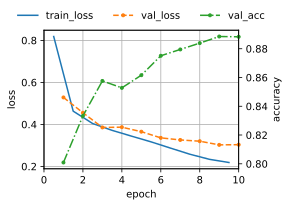

ViT: 6.5M parameters, validation accuracy 0.89


In [8]:
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
trainer.fit(model, data)
vit_history = trainer.history
vit_params, vit_acc = d2l.num_params(model), vit_history['val_acc'][-1]
print(f'ViT: {vit_params/1e6:.1f}M parameters, '
      f'validation accuracy {vit_acc:.2f}')

<!-- d2l:prose id=vision-transformer-md-9 fw=all -->

### The Role of Spatial Position and Learned 2D Grid Topology

Without `pos_embedding`, `ViT` is **permutation-invariant** over the $m = 36$ patches: any permutation of the 36 patches simply permutes rows $1 \dots 36$ of every attention matrix and leaves row $0$ (`<cls>`) literally unchanged. With learned `pos_embedding`, patch $k$ receives positional vector $\mathbf{p}_k$ according to the slot $k$ where it lands. We can test how much the trained `ViT` relies on spatial layout by permuting the 36 patches of each validation image across 5 random permutations at test time (`shuffled_accuracy`):

In [9]:
def shuffle_patches(X, perm, p=16):
    """Move the p x p blocks of images X: block perm[k] goes to grid cell k."""
    n, c, h, w = X.shape
    B = X.reshape(n, c, h // p, p, w // p, p).transpose(3, 4)  # Grid of blocks
    B = B.reshape(n, c, -1, p, p)[:, :, perm]  # Blocks in raster order, moved
    B = B.reshape(n, c, h // p, w // p, p, p).transpose(3, 4)
    return B.reshape(X.shape)

def shuffled_accuracy(model, data, perm):
    """Validation accuracy on images whose blocks are moved by perm."""
    return d2l.evaluate_accuracy(model, ((shuffle_patches(X, perm), y)
                                         for X, y in data.val_dataloader()))

<!-- d2l:prose id=vision-transformer-md-10 fw=all -->

Evaluating `shuffled_accuracy` across five fixed random permutations of the $36$ patches measures how sharply accuracy drops when the spatial layout is scrambled at test time:

In [10]:
rng = np.random.default_rng(0)
perms = [rng.permutation(36) for _ in range(5)]  # Five fixed shuffles
accs = [shuffled_accuracy(model, data, perm) for perm in perms]
print(f'trained ViT: {vit_acc:.3f} as is, '
      f'{min(accs):.2f} to {max(accs):.2f} with its patches shuffled')

trained ViT: 0.888 as is, 0.25 to 0.40 with its patches shuffled


<!-- d2l:prose id=vision-transformer-md-11 fw=all -->

Scrambling the $6 \times 6$ patch arrangement drops validation accuracy from about 0.89 to roughly 0.25–0.45, depending on the shuffle, so the trained `ViT` relies heavily on where each patch sits. It still stays far above the 0.1 of chance, because local $16 \times 16$ patch textures, such as shoe heels or collar shapes, already identify many coarse garment classes as a "bag of patches".

Does the unstructured 1D positional table `pos_embedding` ($36 \times d$) actually discover the 2D geometry of the $6 \times 6$ image grid? Computing the mean cosine similarity between patch position vectors as a function of their 2D grid distance $\max(|r - r'|, |c - c'|)$ on the $6 \times 6$ grid (`grid_similarity`) answers the question; for reference we compute the same curve for a 2D sinusoidal code, which encodes the grid by construction, and for random vectors, which do not:

          learned: +0.04  -0.07  -0.05  -0.05  +0.05
learned - initial: +0.08  -0.10  -0.06  -0.05  +0.15
   2-D sinusoidal: +0.76  +0.21  -0.30  -0.46  -0.36
           random: -0.03  -0.03  -0.03  -0.02  -0.03


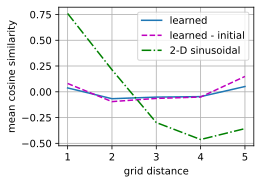

In [11]:
def grid_similarity(P):
    """Mean cosine similarity of 36 position embeddings, by grid distance."""
    P = P - P.mean(0)                    # Drop the part shared by all
    P = P / torch.linalg.vector_norm(P, dim=1, keepdim=True)
    sim = P @ P.T                        # (36, 36) cosine similarities
    rows, cols = torch.meshgrid(torch.arange(6), torch.arange(6),
                                indexing='ij')
    ij = torch.stack((rows.flatten(), cols.flatten()), 1)  # Grid cells
    dist = (ij[:, None] - ij[None]).abs().amax(-1)  # Max of the two offsets
    return [float(sim[dist == k].mean()) for k in range(1, 6)]

S = d2l.sinusoidal_encoding(6, 256)      # 1-D codes of the 6 rows/columns
rows, cols = torch.meshgrid(torch.arange(6), torch.arange(6), indexing='ij')
fixed = torch.cat((S[rows.flatten()], S[cols.flatten()]), 1)  # (36, 512)
learned = model.pos_embedding[0, 1:].detach().cpu()  # Drop the cls slot
noise = torch.randn(36, 512)
curves = {'learned': grid_similarity(learned),
          'learned - initial': grid_similarity(learned - pos_init),
          '2-D sinusoidal': grid_similarity(fixed),
          'random': grid_similarity(noise)}
for name, curve in curves.items():
    print(f'{name:>17}:', '  '.join(f'{c:+.2f}' for c in curve))
d2l.plot(list(range(1, 6)), list(curves.values())[:3], 'grid distance',
         'mean cosine similarity', legend=list(curves)[:3])

<!-- d2l:prose id=vision-transformer-md-12 fw=all -->

After ten epochs the answer is: barely. Only adjacent patches (distance 1) come out slightly more similar than random vectors, with a mean cosine similarity below 0.1 against about $-0.03$ for random vectors; beyond that the learned curve stays flat near zero, and what training added to the initial noise turns positive again at distance 5, where the two patches sit on opposite borders of the image. The 2D sinusoidal code, by contrast, falls from about $0.75$ at distance 1 to well below zero. The clear 2D structure that @Dosovitskiy.Beyer.Kolesnikov.ea.2021 find in ViT position embeddings emerges from far longer training on far larger datasets.

## Comparison with a Parameter-Matched Convolutional Network

How does our 6.5M-parameter `ViT` compare on this 60,000-image dataset against a parameter-matched ResNet-style convolutional baseline (`CompactResNet`, $\approx 6.5\textrm{M}$ parameters) trained for 10 epochs with the exact same cosine AdamW schedule?

In [12]:
class CompactResNet(d2l.Classifier):
    """A ResNet-style CNN parameter-matched to the ViT above."""
    configure_optimizers = ViT.configure_optimizers  # The same recipe

    def __init__(self, num_steps, lr=1e-3, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.LazyConv2d(64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.LazyBatchNorm2d(), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
            d2l.Residual(64), d2l.Residual(64),
            d2l.Residual(128, strides=2), d2l.Residual(128),
            d2l.Residual(256, strides=2), d2l.Residual(256),
            d2l.Residual(512, strides=2),
            nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
            nn.LazyLinear(num_classes))

    def forward(self, X):
        return self.net(X)

    def weight_init(self, module):
        # The Trainer calls this after the first minibatch fixed the shapes
        if type(module) in (nn.Linear, nn.Conv2d):
            nn.init.kaiming_normal_(module.weight, nonlinearity='relu')  # He
            if module.bias is not None:
                nn.init.zeros_(module.bias)

<!-- d2l:prose id=vision-transformer-md-13 fw=all -->

We create a factory `compact_cnn` and instantiate `cnn` with peak learning rate $10^{-3}$:

In [13]:
compact_cnn = lambda: CompactResNet(num_steps, lr=1e-3)  # A fresh CNN
cnn = compact_cnn()

<!-- d2l:prose id=vision-transformer-md-14 fw=all -->

Training `CompactResNet` for 10 epochs (plus a second seed of both `CompactResNet` and `ViT` to check run-to-run stability) compares the two architectures at the exact same $6.5\textrm{M}$-parameter budget:

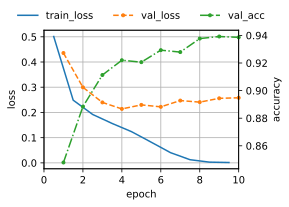

CNN: 6.5M parameters, validation accuracy 0.939, 0.939
ViT: 6.5M parameters, validation accuracy 0.888, 0.889


In [14]:
def final_accuracy(model, data):
    """Validation accuracy after the ten epochs of the first run."""
    trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
    trainer.board.display = False  # No progress plot for the repeats
    trainer.fit(model, data)
    return trainer.history['val_acc'][-1]

trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
trainer.fit(cnn, data)
cnn_history = trainer.history
cnn_params, cnn_acc = d2l.num_params(cnn), cnn_history['val_acc'][-1]
cnn_runs = [cnn_acc, final_accuracy(compact_cnn(), data)]  # Run-to-run range
learned_runs = [vit_acc, final_accuracy(vit(), data)]  # A second ViT run
print(f'CNN: {cnn_params/1e6:.1f}M parameters, validation accuracy',
      ', '.join(f'{a:.3f}' for a in cnn_runs))
print(f'ViT: {vit_params/1e6:.1f}M parameters, validation accuracy',
      ', '.join(f'{a:.3f}' for a in learned_runs))

<!-- d2l:prose id=vision-transformer-md-15 fw=all -->

Overlaying the 10-epoch validation accuracy trajectories of `ViT` and `CompactResNet` highlights the sample-efficiency gap across the entire run:

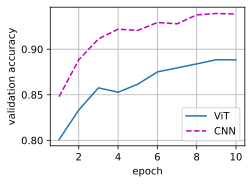

In [15]:
d2l.plot(list(range(1, 11)), [vit_history['val_acc'], cnn_history['val_acc']],
         'epoch', 'validation accuracy', legend=['ViT', 'CNN'])

<!-- d2l:prose id=vision-transformer-md-16 fw=all -->

On a small 60,000-image dataset without data augmentation or large-scale pretraining, `CompactResNet` converges faster and finishes roughly 5 percentage points ahead of `ViT`. This illustrates the fundamental trade-off identified by @Dosovitskiy.Beyer.Kolesnikov.ea.2021: a CNN's hard-coded 2D locality and translation equivariance provide a strong **inductive bias** in the small-data regime, whereas a Vision Transformer learns spatial relationships flexibly from data—trailing CNNs on small unaugmented datasets, but matching or surpassing them when pretrained on tens of millions of images (or trained with strong augmentation, distillation [@touvron2021training], or masked patch reconstruction [@he2022masked]).

## Summary

**Vision Transformers (ViT)** convert an image of shape $(C, H, W)$ into a sequence of $m = (H/p)(W/p)$ tokens via a stride-$p$ convolution (`PatchEmbedding`), prepend a `<cls>` token, add learned 1D positional embeddings, and apply a bidirectional pre-norm Transformer encoder (the figure). Without positional embeddings, a ViT is strictly permutation-invariant over its patches; with learned 1D positional embeddings, the trained model relies heavily on the patch layout, even though ten epochs on Fashion-MNIST imprint the 2D grid onto its position table only faintly. Because ViT lacks the built-in 2D locality and translation equivariance of convolutions, a parameter-matched ResNet outperforms it when trained from scratch on small unaugmented datasets, whereas ViT overtakes CNNs at large pretraining scales and provides a unified token interface for multimodal models.

## Exercises

1. **Patch size $p$, parameter count, and attention FLOPs.** In our $96 \times 96$ `ViT`, the patch size is $p = 16$ ($m = 36$ patches).
   1. How do the parameter count of `PatchEmbedding`, the parameter count of `pos_embedding`, and the parameter count of the $L$ `ViTBlock` layers change when you halve the patch size to $p = 8$ ($m = 144$) or quarter it to $p = 4$ ($m = 576$)?
   2. By what factor does the per-layer attention score matrix size $(m + 1)^2$ grow from $p = 16$ to $p = 8$ and $p = 4$? Train the $p = 8$ `ViT` for 10 epochs and compare its wall-clock time and validation accuracy against $p = 16$.

2. **`<cls>` readout vs. global average pooling.** Replace the `<cls>` token readout in `ViT` with global average pooling across the $m = 36$ patch tokens (`self.head(X[:, 1:].mean(1))`, or removing `cls_token` altogether and averaging all 36 tokens). Train for 10 epochs on Fashion-MNIST and compare validation accuracy against `<cls>` readout.

3. **Exact permutation invariance without positional embeddings.** Set `model.pos_embedding` to all zeros and switch `model` to evaluation mode (disabling dropout). Prove algebraically, and verify numerically on a validation batch to within $10^{-6}$, that applying `shuffle_patches(X, perm)` for any permutation `perm` of $\{0, \dots, 35\}$ leaves the output logits `model(X)` completely unchanged.

4. **Statistical permutation test for 2D grid discovery.** Let $\Delta$ be the difference in `grid_similarity` between adjacent patches (grid distance 1) and patches at grid distance $\ge 4$ for the trained `model.pos_embedding`. Compute the null distribution of $\Delta$ across 1,000 random permutations of the 36 rows of `pos_embedding`, and report the empirical $p$-value. Is the faint grid structure of the learned positional embeddings distinguishable from chance?

5. **Sub-patch vs. whole-patch translation sensitivity.** In a CNN, shifting an input image by $s$ pixels shifts the internal feature maps by $s$ pixels (up to pooling stride). In `ViT` ($p = 16$), shifting an image by $s = 16$ pixels (one full patch width) merely shifts each patch into the adjacent patch slot, whereas shifting by $s = 8$ pixels (half a patch) cuts across every $16 \times 16$ patch boundary. Evaluate the validation accuracy of our trained `ViT` and `CompactResNet` on validation images shifted right by $s \in \{0, 2, 4, 8, 12, 16\}$ pixels (zero-padding the left border). Why does `ViT` show a non-monotonic dip at $s = 8$ relative to $s = 16$?

6. **Mean attention distance across depth.** @Dosovitskiy.Beyer.Kolesnikov.ea.2021 define a head's **mean attention distance** as the attention-weighted average 2D Euclidean pixel distance $\sum_{i,j=1}^{36} \alpha_{ij} \, d_{\textrm{pixel}}(i, j) / 36$ between query patch $i$ and key patch $j$. Compute the mean attention distance for each of the 8 heads in blocks 1 and 2 of our trained `ViT`. Do early-layer heads attend more locally than deeper-layer heads, analogous to the growing receptive field of a CNN?

[Discussions](https://d2l.discourse.group/t/36778)